# 03 — Features (the last data step)

**In plain words:** notebooks 01–02 told us *which* lakes exist, *when* they burst and *how big* they were. This
notebook adds the other things that may explain **why** a lake bursts, for every lake and every year, and builds the
two tables the models will use.

| Output | What it is |
| --- | --- |
| `lake_year.parquet` / `.csv` | **Tier 1 table:** one row per lake per year (552 × 26): the label `glof` + 18 features |
| `lake_week.parquet` / `.csv` | **Tier 2 table:** one row per special lake per week (2015–2025): area, 2-week growth, heat, rain, evaluation label |
| `data_dictionary.csv` | what every column means, its unit, source and time rule |
| `its_live_speed.csv`, `era5_season.csv`, `era5_daily_tier2.csv`, `terrain.csv` | the raw inputs behind the features |
| `fig_03_glacier_speed.png`, `run_info.json` | glacier speed of the Tier 2 glaciers, and a record of the run |

**The one rule that must never break (leakage):** a feature for year Y may only use information up to
**31 December of year Y−1**, because on 1 January we cannot know the future. Step 5 checks this on the real data:
it scrambles every value from year Y onwards and confirms the features for year Y do not change.

**Gate 2:** after this notebook the dataset is **frozen**: no new features are added later.


## 0. Setup
Same as before: the tested code in `src/karaglof/` and the committed tables in `data/` come from the GitHub repository.
`rasterio` reads the ITS_LIVE glacier-speed files directly from the cloud.

In [1]:
import os
import subprocess
import sys

REPO_URL = "https://github.com/inamjadoon/KaraGlof.git"
REPO_DIR = "/content/KaraGlof"
if os.path.isdir(REPO_DIR):
    subprocess.run(["git", "-C", REPO_DIR, "pull", "-q"], check=True)
else:
    subprocess.run(["git", "clone", "-q", REPO_URL, REPO_DIR], check=True)
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "rasterio"], check=True)
sys.path.insert(0, f"{REPO_DIR}/src")
print(subprocess.run(["git", "-C", REPO_DIR, "log", "-1", "--oneline"],
                     capture_output=True, text=True).stdout)

fb4eb1a fix(notebook03): glacier speed from all ice within 3 km, 90th percentile



In [2]:
import json
import time
from datetime import UTC, datetime
from pathlib import Path

import ee
import geemap
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from google.colab import drive
from rasterio.features import geometry_mask
from rasterio.windows import Window, from_bounds

from karaglof import features as kf

ee.Authenticate()
ee.Initialize(project="glof-497313")

drive.mount("/content/drive")
OUT = Path("/content/drive/MyDrive/KaraGlof/03_features")
OUT.mkdir(parents=True, exist_ok=True)
DATA = Path(REPO_DIR) / "data"
EXPORT_FOLDER = "KaraGlof_exports"
print("outputs ->", OUT)

Mounted at /content/drive
outputs -> /content/drive/MyDrive/KaraGlof/03_features


## Parameters
* **Years:** features for 2000–2025. Each feature looks back, so the inputs start earlier (climate from 1980 for the
  baseline, glacier speed from 1993 for the 5-year surge baseline before 2000).
* **Glacier speed** is the speed of the **fastest 10%** of all glacier ice within `VEL_NEAR_M` of the lake. The
  first run used the median of the nearest ("parent") glacier only, and Shisper showed 3–8 m/yr even in its famous
  2017–2019 surge: for an ice-dammed lake the nearest glacier is often the slow one that *feeds* the lake, not the
  one that *dams* it. Taking all nearby ice and its fastest part captures whichever glacier is surging next to the
  lake. The median is kept in `its_live_speed.csv` for transparency. ITS_LIVE annual mosaics exist up to **2022**, so speed features
  for 2024 and 2025 (which need 2023 and 2024) are empty. That is stated, not guessed.
* **Surge:** a glacier is "surging" when its speed is at least `SURGE_FACTOR` times its median of the 5 years before.
* **Climate** is the May–September melt season from ERA5-Land at the lake. Anomalies are measured against
  **1980–1999**, entirely before the study period, so no anomaly can carry information from a later year.

In [3]:
YEARS = list(range(2000, 2026))
VEL_YEARS = list(range(1993, 2023))      # ITS_LIVE v2 annual mosaics end in 2022
ITS_LIVE_URL = ("https://its-live-data.s3.amazonaws.com/velocity_mosaic/v2/annual/cog/"
                "ITS_LIVE_velocity_120m_RGI14A_{year}_v02_v.tif")
VEL_NEAR_M = 3_000                       # glacier speed measured on all ice within 3 km of the lake
VEL_QUANTILE = 0.9                       # feature = speed of the fastest 10% of that ice
SURGE_FACTOR = 2.0                       # surge = speed >= 2 x the median of the 5 years before
CLIMATE_YEARS = list(range(1980, 2025))  # 1980-1999 baseline + 1999-2024 for features of 2000-2025
SEASON = ("05-01", "10-01")              # May to September (end date exclusive)
RING_M = 300                             # terrain slope measured in a 300 m ring around the lake
WEEK_START, WEEK_END = "2015-01-01", "2025-12-31"
UTM = "EPSG:32643"

## Helper: Earth Engine exports (same as notebooks 01–02)
Big results go to Drive and are cached; reruns read the saved file.

In [4]:
EXPORTS = Path("/content/drive/MyDrive") / EXPORT_FOLDER

def export(fc, name, fmt="CSV"):
    path = EXPORTS / f"{name}.{fmt.lower()}"
    if path.exists():
        print(f"{name}: cached file found, nothing to recompute")
        return path, None
    desc = f"karaglof_{name}"
    for t in ee.batch.Task.list()[:30]:
        st = t.status()
        if st.get("description") == desc and st.get("state") in ("READY", "RUNNING"):
            print(f"{name}: the same export is already running, waiting for it")
            return path, t
    task = ee.batch.Export.table.toDrive(collection=fc, description=desc, folder=EXPORT_FOLDER,
                                         fileNamePrefix=name, fileFormat=fmt)
    task.start()
    print(f"{name}: export started (watch it at https://code.earthengine.google.com/tasks)")
    return path, task

def read_export(path, task):
    t0 = time.time()
    while task is not None and task.active():
        print(f"\r{path.stem}: {task.status()['state']} for {(time.time() - t0) / 60:.0f} min ", end="")
        time.sleep(30)
    if task is not None and task.status()["state"] != "COMPLETED":
        raise RuntimeError(task.status())
    for _ in range(60):
        if path.exists():
            break
        time.sleep(10)
    print(f"\n{path.stem}: ready")
    return gpd.read_file(path) if path.suffix == ".geojson" else pd.read_csv(path)

def to_ee(gdf, cols=("lake_id",)):
    small = gdf[list(cols) + ["geometry"]].copy()
    small["geometry"] = small.geometry.set_precision(1e-6)
    return ee.FeatureCollection([ee.Feature(f) for f in json.loads(small.to_json())["features"]])

## 1. Load the committed tables
Lakes, events (database + news) and yearly/weekly lake areas come from the repository (`data/labels`, `data/area`),
so every number here traces back to a commit. The glacier outlines (RGI v7) are the ones notebook 01 exported to
Drive; if that file is missing they are exported again.

In [5]:
lakes = gpd.read_file(DATA / "labels" / "lakes_polygons.geojson")
events = pd.read_csv(DATA / "labels" / "events.csv")
area_yearly = pd.read_csv(DATA / "area" / "lake_area_yearly.csv")
area_weekly = pd.read_csv(DATA / "area" / "lake_area_weekly.csv")
tier2 = lakes[lakes.tier2]
TIER2_IDS = dict(zip(tier2.name, tier2.lake_id, strict=True))

glacier_file = EXPORTS / "glaciers_rgi7.geojson"
if glacier_file.exists():
    glaciers = gpd.read_file(glacier_file)
else:
    rgi = ee.FeatureCollection("projects/sat-io/open-datasets/RGI/RGI_VECTOR_MERGED_V7").filterBounds(
        ee.Geometry.Rectangle(list(lakes.total_bounds)).buffer(15_000))
    glaciers = read_export(*export(rgi.select(["rgi_id"]).map(lambda f: f.simplify(maxError=30)),
                                   "glaciers_rgi7", fmt="GeoJSON"))
print(f"{len(lakes)} lakes, {len(events)} events, {len(glaciers)} glacier outlines")   # 📋 REPORT

552 lakes, 20 events, 7497 glacier outlines


## 2. Glacier speed from ITS_LIVE (1993–2022)
ITS_LIVE (NASA) publishes one map of glacier surface speed per year (120 m pixels, from satellite image pairs). Each
yearly file is ~700 MB, but it is a *cloud-optimised GeoTIFF*: only the window over our basins is downloaded.

For every lake, the **speed zone** is all glacier ice (RGI v7 outlines) within `VEL_NEAR_M` of the lake. If no
glacier is that close, the zone is the parent glacier up to `VEL_NEAR_M` beyond its closest point. The lake's speed
for a year is the speed of the **fastest 10%** of the pixels in that zone (`VEL_QUANTILE`); the median is saved too.
A surge (a glacier suddenly flowing many times faster, like Shisper in 2017–2019) shows up as a jump in this number.

In [6]:
lakes_utm = lakes.to_crs(UTM)
glaciers_utm = glaciers.to_crs(UTM).set_index("rgi_id")
ice_index = glaciers_utm.geometry.sindex
zones = []
for lake in lakes_utm.itertuples():
    near = lake.geometry.buffer(VEL_NEAR_M)
    hits = glaciers_utm.geometry.iloc[ice_index.query(near, predicate="intersects")]
    if len(hits):                                   # all glacier ice within 3 km of the lake
        zones.append(hits.union_all().intersection(near))
        continue
    parent = glaciers_utm.geometry.get(lake.glacier_id)
    if parent is None:
        zones.append(None)
        continue
    reach = lake.geometry.distance(parent) + VEL_NEAR_M
    zones.append(parent.intersection(lake.geometry.buffer(reach)))
zones = gpd.GeoDataFrame({"lake_id": lakes.lake_id.values}, geometry=zones, crs=UTM)
print("lakes with a speed zone:", int(zones.geometry.notna().sum()), "of", len(zones))

rows, masks, grid = [], None, None
with rasterio.Env(GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR", AWS_NO_SIGN_REQUEST="YES"):
    for year in VEL_YEARS:
        with rasterio.open("/vsicurl/" + ITS_LIVE_URL.format(year=year)) as src:
            zsrc = zones.dropna(subset=["geometry"]).to_crs(src.crs)
            w = from_bounds(*zsrc.total_bounds, transform=src.transform)
            w = Window(int(w.col_off) - 2, int(w.row_off) - 2, int(w.width) + 4, int(w.height) + 4)
            speed = src.read(1, window=w, masked=True).astype(float).filled(np.nan)
            transform = src.window_transform(w)
            if (transform, speed.shape) != grid:        # same grid every year -> masks built once
                grid = (transform, speed.shape)
                masks = {z.lake_id: np.nonzero(geometry_mask([z.geometry], speed.shape, transform, invert=True))
                         for z in zsrc.itertuples() if not z.geometry.is_empty}
        for lake_id, idx in masks.items():
            v = speed[idx]
            v = v[np.isfinite(v)]
            rows.append({"lake_id": lake_id, "year": year,
                         "v_m_per_yr": float(np.quantile(v, VEL_QUANTILE)) if len(v) else np.nan,
                         "v_median_m_per_yr": float(np.median(v)) if len(v) else np.nan,
                         "n_px": int(len(v))})
        print(f"\r{year} done", end="")
velocity = pd.DataFrame(rows)
print("\nlake-years with a glacier speed:", f"{velocity.v_m_per_yr.notna().mean():.0%}")   # 📋 REPORT
t2v = velocity[velocity.lake_id.isin(TIER2_IDS.values())].replace({"lake_id": {v: k for k, v in TIER2_IDS.items()}})
print("Fastest 10% of ice within 3 km (the feature), m/yr:")
print(t2v.pivot(index="year", columns="lake_id", values="v_m_per_yr").round(0).loc[2010:].T.to_string())
print("Median (for comparison), m/yr:")
print(t2v.pivot(index="year", columns="lake_id", values="v_median_m_per_yr").round(0).loc[2010:].T.to_string())

lakes with a speed zone: 552 of 552
2022 done
lake-years with a glacier speed: 99%
Fastest 10% of ice within 3 km (the feature), m/yr:
year        2010   2011   2012   2013   2014   2015   2016   2017   2018   2019   2020   2021   2022
lake_id                                                                                             
Khurdopin   19.0   23.0   23.0   31.0   41.0   41.0  147.0  154.0   65.0   23.0   28.0   16.0   16.0
Passu      285.0  253.0  283.0  284.0  283.0  298.0  296.0  306.0  290.0  302.0  293.0  311.0  292.0
Shisper     21.0   27.0   19.0   13.0    9.0   10.0    9.0    9.0   18.0   66.0   33.0   33.0   34.0
Median (for comparison), m/yr:
year       2010  2011  2012  2013  2014  2015  2016  2017   2018   2019   2020   2021   2022
lake_id                                                                                     
Khurdopin   5.0   7.0   6.0   7.0   7.0   6.0  12.0  94.0   20.0   11.0   14.0    7.0    9.0
Passu      28.0  35.0  15.0  43.0  38.0  33.0  74.

## 3. Climate from ERA5-Land
ERA5-Land (ECMWF) gives daily weather on a ~9–11 km grid; each lake takes the grid cell it sits in.
* **Yearly, all lakes (1980–2024):** for each melt season (May–September): positive degree-days (sum of daily mean
  temperatures above 0 °C, a measure of melt energy), mean temperature, precipitation and snowmelt.
* **Daily, the 3 Tier 2 lakes (1980–2025):** daily mean temperature and precipitation, for the weekly warning table.

A ~10 km cell is much lower on average than a high glacial lake, so absolute temperatures are too warm; the
*anomalies* (difference from the lake's own 1980–1999 normal) are what the models use for heat.

In [7]:
points = gpd.GeoDataFrame(lakes[["lake_id"]].copy(),
                          geometry=gpd.points_from_xy(lakes.lon, lakes.lat), crs="EPSG:4326")
points_fc = to_ee(points)
t2_points_fc = to_ee(points[points.lake_id.isin(TIER2_IDS.values())])
era = ee.ImageCollection("ECMWF/ERA5_LAND/DAILY_AGGR")

def season(year):
    d = era.filterDate(f"{year}-{SEASON[0]}", f"{year}-{SEASON[1]}")
    t = d.select("temperature_2m").map(lambda i: i.subtract(273.15))
    img = ee.Image.cat(t.map(lambda i: i.max(0)).sum().rename("pdd"), t.mean().rename("t_mean_c"),
                       d.select("total_precipitation_sum").sum().multiply(1000).rename("precip_mm"),
                       d.select("snowmelt_sum").sum().multiply(1000).rename("snowmelt_mm"))
    return img.reduceRegions(points_fc, ee.Reducer.first(), 11132).map(lambda f, year=year: f.set("year", year))

season_fc = ee.FeatureCollection([season(y) for y in CLIMATE_YEARS]).flatten()
climate = read_export(*export(season_fc.select(["lake_id", "year", "pdd", "t_mean_c", "precip_mm", "snowmelt_mm"]),
                              "era5_season_1980_2024"))

def day(img):
    v = ee.Image.cat(img.select("temperature_2m").subtract(273.15).rename("t2m_c"),
                     img.select("total_precipitation_sum").multiply(1000).rename("precip_mm"))
    return v.reduceRegions(t2_points_fc, ee.Reducer.first(), 11132).map(
        lambda f: f.set("date", img.date().format("YYYY-MM-dd")))

daily_fc = era.filterDate("1980-01-01", "2026-01-01").map(day).flatten()
daily = read_export(*export(daily_fc.select(["lake_id", "date", "t2m_c", "precip_mm"]), "era5_daily_tier2_1980_2025"))
print(f"season rows: {len(climate)}; daily rows: {len(daily)}; last daily date: {daily.date.max()}")   # 📋 REPORT

era5_season_1980_2024: cached file found, nothing to recompute

era5_season_1980_2024: ready
era5_daily_tier2_1980_2025: cached file found, nothing to recompute

era5_daily_tier2_1980_2025: ready
season rows: 24840; daily rows: 50406; last daily date: 2025-12-31


## 4. Terrain (static)
* **Elevation** of the lake and **slope** in a `RING_M` ring around it, from NASADEM (the 2000 SRTM radar mission,
  before the study period, so it cannot carry future information).
* **Distance to the parent glacier** and the **parent glacier's area**, from the RGI v7 outlines (~2000).

In [8]:
dem = ee.Image("NASA/NASADEM_HGT/001").select("elevation")
slope = ee.Terrain.slope(dem)
rings = gpd.GeoDataFrame(lakes[["lake_id"]].copy(),
                         geometry=[g.buffer(RING_M).difference(g) for g in lakes_utm.geometry], crs=UTM).to_crs("EPSG:4326")
elev = dem.reduceRegions(to_ee(lakes), ee.Reducer.mean(), 30).getInfo()["features"]
slp = slope.reduceRegions(to_ee(rings), ee.Reducer.mean(), 30).getInfo()["features"]
terrain = pd.DataFrame({"lake_id": [f["properties"]["lake_id"] for f in elev],
                        "elev_m": [f["properties"].get("mean") for f in elev]})
terrain = terrain.merge(pd.DataFrame({"lake_id": [f["properties"]["lake_id"] for f in slp],
                                      "slope_around_deg": [f["properties"].get("mean") for f in slp]}), on="lake_id")
parent = glaciers_utm.geometry.reindex(lakes_utm.glacier_id).values
terrain["dist_to_glacier_m"] = [round(g.distance(p)) if p is not None else np.nan
                                for g, p in zip(lakes_utm.geometry, parent, strict=True)]
terrain["parent_glacier_km2"] = [round(p.area / 1e6, 3) if p is not None else np.nan for p in parent]
terrain = terrain.round({"elev_m": 0, "slope_around_deg": 1})
print(terrain.describe().round(1).to_string())   # 📋 REPORT

       elev_m  slope_around_deg  dist_to_glacier_m  parent_glacier_km2
count   552.0             552.0              552.0               552.0
mean   3920.7              28.7             1741.2                39.3
std     668.2              10.7             1627.6               132.0
min    1715.0               2.0                0.0                 0.0
25%    3516.5              21.0              628.8                 0.1
50%    4080.5              28.5             1354.0                 0.6
75%    4421.5              37.6             2270.2                 4.1
max    5448.0              52.9             9193.0               789.6


## 5. Tier 1 table `lake_year` and the leakage check REPORT
`karaglof.features.build_lake_year` shifts every yearly input forward one year, so the row for year Y only sees
years ≤ Y−1. `check_no_future_leak` then **proves it on the real data**: for every year Y, it replaces every input
value from year Y onwards with random numbers and confirms that not a single feature for year Y changes.

In [9]:
def build(lakes, events, area, velocity, climate, terrain):
    return kf.build_lake_year(lakes, events, area, velocity, climate, terrain, YEARS)

sources = {"lakes": lakes[["lake_id"]], "events": events, "area": area_yearly,
           "velocity": velocity, "climate": climate, "terrain": terrain}
lake_year = build(**sources)
for year in YEARS:
    kf.check_no_future_leak(build, sources, year)
print(f"Leakage check: PASS for all {len(YEARS)} years "
      "(no feature for year Y changes when data from Y onwards is scrambled)")

print(f"\nlake_year: {len(lake_year)} rows, {lake_year.glof.sum()} positive lake-years")
split = pd.cut(lake_year.year, [1999, 2017, 2019, 2025], labels=["train", "validation", "test"])
print(lake_year.groupby(split, observed=False).glof.agg(["size", "sum"])
      .rename(columns={"size": "lake_years", "sum": "positives"}).to_string())
print("\nShare of empty values per feature:")
print(lake_year[kf.FEATURES].isna().mean().round(3).to_string())

Leakage check: PASS for all 26 years (no feature for year Y changes when data from Y onwards is scrambled)

lake_year: 14352 rows, 15 positive lake-years
            lake_years  positives
year                             
train             9936          7
validation        1104          3
test              3312          5

Share of empty values per feature:
area_km2_prev              0.060
area_growth_3y_pct         0.190
area_trend_km2_per_yr      0.128
velocity_prev              0.085
velocity_change            0.085
surge_ratio_prev           0.085
surge_flag_prev            0.085
pdd_prev_summer            0.000
heat_anomaly_prev          0.000
precip_prev_summer_mm      0.000
snowmelt_prev_summer_mm    0.000
elev_m                     0.000
slope_around_deg           0.000
dist_to_glacier_m          0.000
parent_glacier_km2         0.000


## 6. Tier 2 table `lake_week` REPORT
For Shisper, Khurdopin and Passu, one row per week 2015–2025:
* `area_km2` / `n_obs`: weekly lake area from notebook 02 (empty when cloudy);
* `area_change_2w_pct`: growth against the most recent measured area 2–4 weeks earlier (only earlier weeks);
* `t2m_anomaly_c`, `pdd_7d`, `rain_7d_mm`: heat and rain of that week vs the 1980–1999 normal for that week of year;
* `event_in_window`: **evaluation only, never a feature**: 1 if a day-dated drainage follows within 14 days, empty if
  the outburst is known only to the month.

In [10]:
daily["date"] = pd.to_datetime(daily.date)
clim_week = kf.weekly_climate(daily)
area_weekly["week_start"] = pd.to_datetime(area_weekly.week_start)
lake_week = kf.build_lake_week(area_weekly, clim_week, events[events.lake_id.isin(TIER2_IDS.values())])
lake_week = lake_week[(lake_week.week_start >= WEEK_START) & (lake_week.week_start <= WEEK_END)]
names = {v: k for k, v in TIER2_IDS.items()}
summary = lake_week.groupby("lake_id").agg(weeks=("week_start", "size"), with_area=("area_km2", "count"),
                                           with_growth=("area_change_2w_pct", "count"),
                                           with_heat=("t2m_anomaly_c", "count"),
                                           event_weeks=("event_in_window", "sum"),
                                           unknown_weeks=("event_in_window", lambda s: int(s.isna().sum())))
print(summary.rename(index=names).to_string())

           weeks  with_area  with_growth  with_heat  event_weeks  unknown_weeks
lake_id                                                                        
Passu        574        359          336        573          0.0              0
Shisper      574        355          326        573          8.0             21
Khurdopin    574        389          376        573          6.0             13


## 7. Save, data dictionary and Gate 2

In [11]:
lake_year.to_parquet(OUT / "lake_year.parquet", index=False)
lake_year.to_csv(OUT / "lake_year.csv", index=False)
lake_week.to_parquet(OUT / "lake_week.parquet", index=False)
lake_week.assign(week_start=lake_week.week_start.dt.strftime("%Y-%m-%d")).to_csv(OUT / "lake_week.csv", index=False)
velocity.to_csv(OUT / "its_live_speed.csv", index=False)
climate.to_csv(OUT / "era5_season.csv", index=False)
daily.to_csv(OUT / "era5_daily_tier2.csv", index=False)
terrain.to_csv(OUT / "terrain.csv", index=False)
pd.DataFrame([{"column": c, "meaning": m, "unit": u, "source": s, "time_rule": r}
              for c, (m, u, s, r) in kf.DATA_DICTIONARY.items()]).to_csv(OUT / "data_dictionary.csv", index=False)
run_info = {
    "notebook": "03_features", "run_utc": datetime.now(UTC).isoformat(timespec="seconds"),
    "sources": {"glacier_speed": "ITS_LIVE v2 annual mosaics, RGI14A, 120 m (its-live-data S3, COG)",
                "climate": "ECMWF/ERA5_LAND/DAILY_AGGR", "terrain": "NASA/NASADEM_HGT/001",
                "glaciers": "RGI v7 (notebook 01 export)", "lakes_events_area": "data/labels, data/area"},
    "parameters": {k: v for k, v in globals().items() if k.isupper() and k not in ("OUT", "REPO_DIR", "DATA")
                   and isinstance(v, int | float | str | list | tuple | dict)},
    "counts": {"lake_years": len(lake_year), "positives": int(lake_year.glof.sum()), "lake_weeks": len(lake_week)},
    "leakage_check": f"PASS for {YEARS[0]}-{YEARS[-1]}",
    "missing_share": lake_year[kf.FEATURES].isna().mean().round(3).to_dict(),
    "gate_2": "dataset frozen: no new features after this notebook",
    "versions": {"earthengine-api": ee.__version__, "geemap": geemap.__version__,
                 "pandas": pd.__version__, "rasterio": rasterio.__version__},
}
(OUT / "run_info.json").write_text(json.dumps(run_info, indent=2, default=str))
print(sorted(p.name for p in OUT.iterdir()))
print("Gate 2: dataset frozen. No new features are added after this notebook.")

['data_dictionary.csv', 'era5_daily_tier2.csv', 'era5_season.csv', 'fig_03_glacier_speed.png', 'its_live_speed.csv', 'lake_week.csv', 'lake_week.parquet', 'lake_year.csv', 'lake_year.parquet', 'run_info.json', 'terrain.csv']
Gate 2: dataset frozen. No new features are added after this notebook.


## 8. Figure: glacier speed of the Tier 2 glaciers REPORT
The blue line is the feature (fastest 10% of ice within 3 km), the grey dashes the median; red lines are outbursts. The research question in one
picture: **do the surges (sudden jumps) come before the outbursts?**

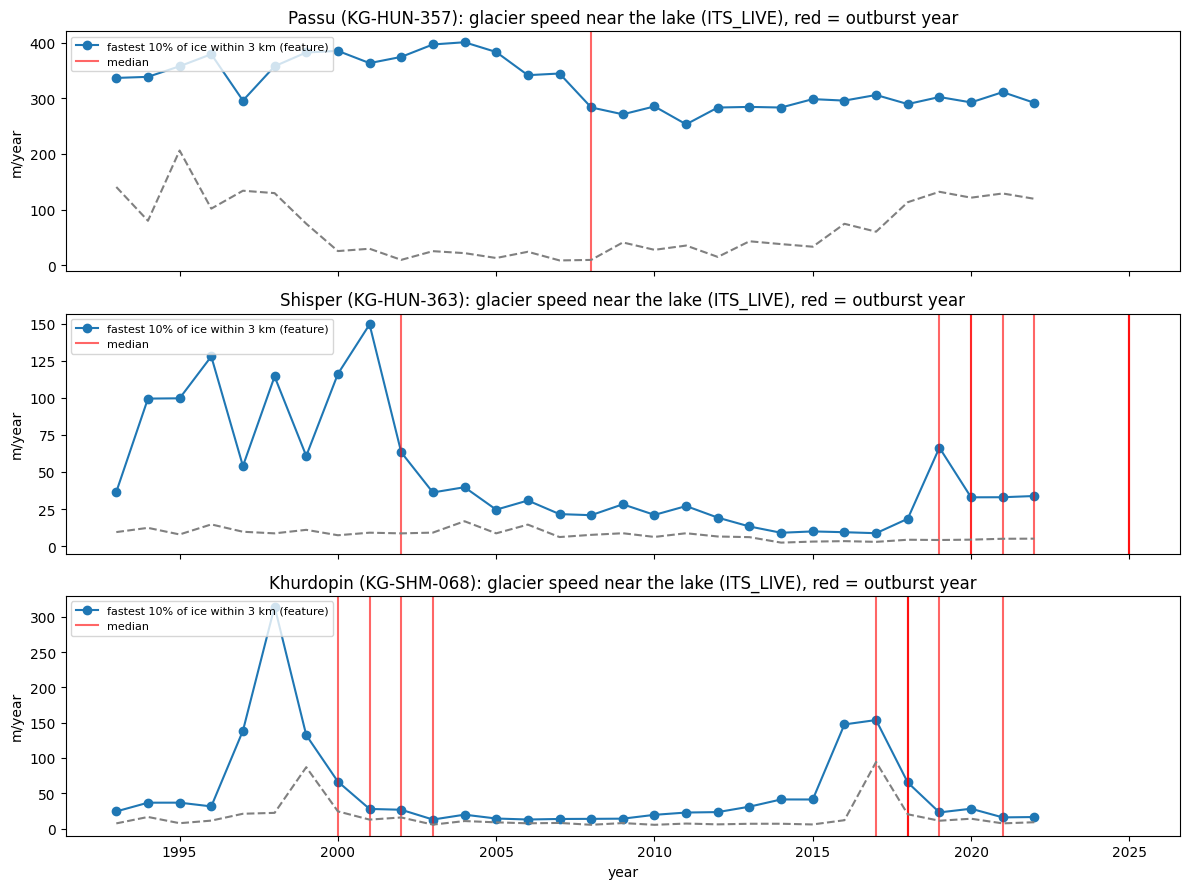

In [12]:
fig, axes = plt.subplots(len(TIER2_IDS), 1, figsize=(12, 3 * len(TIER2_IDS)), sharex=True)
for ax, (name, lid) in zip(axes, TIER2_IDS.items(), strict=True):
    v = velocity[velocity.lake_id == lid]
    ax.plot(v.year, v.v_m_per_yr, marker="o", color="#1f77b4")
    for d in events[events.lake_id == lid].date:
        ax.axvline(int(d[:4]), color="red", alpha=0.6)
    ax.plot(v.year, v.v_median_m_per_yr, ls="--", color="grey", label="median (for comparison)")
    ax.legend(["fastest 10% of ice within 3 km (feature)", "median"], fontsize=8, loc="upper left")
    ax.set_title(f"{name} ({lid}): glacier speed near the lake (ITS_LIVE), red = outburst year")
    ax.set_ylabel("m/year")
ax.set_xlabel("year")
fig.tight_layout()
fig.savefig(OUT / "fig_03_glacier_speed.png", dpi=150)
plt.show()